# Tahap 3a — Arah & kecepatan gerak pasien dari skeleton

Versi ringkas dari `03_motion.ipynb`: **hanya arah dan kecepatan**, tanpa IMU. Memakai keypoint RTMPose (Halpe-26) dari
Tahap 2 pada kotak **pasien** hasil Bagian B `02b_analysis.ipynb` (track terkoreksi dari sel 14 dipakai jika ada).

| Besaran | Dihitung dari | Satuan |
|---|---|---|
| **Kecepatan tubuh** | titik tengah kedua pergelangan kaki (ankle) | m/s (perkiraan) |
| **Kecepatan kaki** kiri / kanan | masing-masing ankle | m/s (perkiraan) |
| **Arah gerak** | arah perpindahan titik tengah di gambar | derajat (0° = kanan, 90° = atas gambar, ±180° = kiri, −90° = bawah) + label |
| **Mendekat / menjauh kamera** | perubahan ukuran tubuh di gambar (skala) | % per detik |

**Grafik per video:** kecepatan terhadap waktu, arah terhadap waktu, mendekat/menjauh, diagram mawar arah, dan lintasan
berwarna menurut kecepatan. **Grafik semua video:** median kecepatan per video dan porsi tiap arah per video.

> Arah & kecepatan adalah **proyeksi di bidang kamera** (2D). Gerak lurus ke arah kamera hampir tidak menggeser titik di gambar,
> jadi tampak sebagai "diam" di arah, tetapi terlihat di panel *mendekat/menjauh*. m/s memakai panjang tulang kering
> yang diasumsikan (`SHANK_LEN_M`), jadi anggap sebagai perkiraan.

### Letak berkas
```
FOG/
├── 03a_arah_kecepatan.ipynb
├── data/stage2/.../<RUN_NAME>/npz/*.npz           ← hasil Tahap 2
└── outputs/
    ├── 02b_analysis/<RUN_NAME>/identity/          ← dari 02b (sel 12, dan sel 14 jika sudah review)
    └── 03a_arah_kecepatan/<RUN_NAME>/             ← DIBUAT NOTEBOOK INI
        ├── frames/<video_id>.csv    ← per frame: posisi, kecepatan, arah
        ├── per_video_summary.csv    ← per video: median/maks kecepatan, porsi tiap arah
        └── figures/<video_id>_*.png, semua_video_*.png
```
Butuh: `numpy pandas scipy matplotlib`. Lalu **Run All**.

## 1. Pengaturan

In [1]:
DATA_DIR              = "data"
OUTPUT_ROOT           = "."
RUN_NAME              = None     # None = run Tahap 2 dengan video terbanyak
POSE_DIR_OVERRIDE     = None
IDENTITY_DIR_OVERRIDE = None

USE_CORRECTED = True             # pakai identity/patient_corrected (hasil review) bila ada
SKIP_QUALITY  = {"label_wrong", "observer_in_box", "patient_missing", "other_anomaly"}
KPT_THR       = 0.3              # skor keypoint minimal
MAX_GAP_S     = 0.4              # celah keypoint <= ini diisi interpolasi
SMOOTH_HZ     = 3.0              # low-pass posisi sebelum menghitung kecepatan (lebih kecil = lebih halus)

SHANK_LEN_M   = 0.40             # panjang lutut-ankle yang diasumsikan, untuk mengubah ke meter
SCALE_WIN_S   = 2.0              # skala = persentil-90 panjang tulang kering dalam jendela ini
MOVE_MIN_MPS  = 0.10             # kecepatan tubuh di bawah ini = "diam" (arah tidak dihitung)
APPROACH_MIN  = 0.05             # |laju perubahan skala| (per detik) di atas ini = mendekat / menjauh

VIEW_VIDEO     = None            # video yang ditampilkan di sel 5; None = video dengan data kaki terbanyak
SAVE_ALL_FIGS  = True            # simpan grafik per video untuk SEMUA video ke figures/ (hanya VIEW_VIDEO yang ditampilkan)

CELLS_DONE = set()
CELL_TITLES = {"settings": "1. Pengaturan", "paths": "2. Lokasi data", "functions": "3. Fungsi",
               "extract": "4. Hitung semua video", "one-video": "5. Grafik satu video", "overview": "6. Grafik semua video"}
def _done(name):
    CELLS_DONE.add(name)
def _require(*names):
    missing = [CELL_TITLES[n] for n in names if n not in CELLS_DONE]
    if missing:
        raise RuntimeError("Belum selesai: " + ", ".join(missing) + ". Jalankan sel-sel itu berurutan dan perbaiki "
                           "error PERTAMA yang muncul.")
_done('settings')

## 2. Lokasi data

In [3]:
if "CELLS_DONE" not in globals():
    raise RuntimeError("Jalankan sel 1 (Pengaturan) dulu: kernel di-restart atau ada sel yang terlewat.")
_require('settings')

import json, os, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display
try:
    from scipy.signal import butter, filtfilt
except ImportError as e:
    raise ImportError("Butuh scipy: pip install scipy (atau sudo apt install python3-scipy), lalu restart kernel.") from e
warnings.filterwarnings("ignore", category=RuntimeWarning)

INPUT_ROOT = Path(DATA_DIR).resolve()
WORK_ROOT  = Path(OUTPUT_ROOT).resolve()
if not INPUT_ROOT.exists():
    raise RuntimeError(f"Folder data {INPUT_ROOT} tidak ada (notebook berjalan di {Path.cwd()}). Ubah DATA_DIR.")

def npz_dirs():
    if POSE_DIR_OVERRIDE:
        return [Path(POSE_DIR_OVERRIDE)]
    found = set()
    for root in (INPUT_ROOT, WORK_ROOT / "outputs" / "02_pose"):
        if root.exists():
            found |= {f.parent.resolve() for f in root.rglob("*.npz") if f.parent.name == "npz"}
    return sorted(found)

cands = [(p, len(list(p.glob("*.npz")))) for p in npz_dirs()]
cands = [c for c in cands if c[1] > 0 and (not RUN_NAME or c[0].parent.name == RUN_NAME)]
if not cands:
    raise RuntimeError("Hasil Tahap 2 (folder 'npz' berisi .npz) tidak ditemukan di data/. Atur POSE_DIR_OVERRIDE.")
NPZ_DIR = max(cands, key=lambda c: c[1])[0]
RUN_NAME = NPZ_DIR.parent.name

if IDENTITY_DIR_OVERRIDE:
    ID_DIR = Path(IDENTITY_DIR_OVERRIDE)
else:
    opts = [WORK_ROOT / "outputs" / "02b_analysis" / RUN_NAME / "identity"]
    opts += sorted(p.parent for p in WORK_ROOT.glob("outputs/02b_analysis/*/identity/identity_summary.csv"))
    opts += sorted(p.parent for p in INPUT_ROOT.rglob("identity_summary.csv"))
    ID_DIR = next((p for p in opts if (p / "identity_summary.csv").exists()), None)
if ID_DIR is None or not (ID_DIR / "identity_summary.csv").exists():
    raise RuntimeError("identity/identity_summary.csv tidak ditemukan. Jalankan dulu sel 10-12 02b_analysis.ipynb, "
                       "atau atur IDENTITY_DIR_OVERRIDE.")
IDSUM = pd.read_csv(ID_DIR / "identity_summary.csv", dtype={"video_id": str}).set_index("video_id")
VIDEO_IDS = [v for v in sorted(p.stem for p in NPZ_DIR.glob("*.npz"))
             if v in IDSUM.index and (ID_DIR / "patient" / f"{v}.csv").exists()]
OUT_DIR = WORK_ROOT / "outputs" / "03a_arah_kecepatan" / RUN_NAME
FIG_DIR, FRAME_DIR = OUT_DIR / "figures", OUT_DIR / "frames"
for d in (FIG_DIR, FRAME_DIR):
    d.mkdir(parents=True, exist_ok=True)
n_corr = sum((ID_DIR / "patient_corrected" / f"{v}.csv").exists() for v in VIDEO_IDS)
print(f"Skeleton : {NPZ_DIR}\nIdentitas: {ID_DIR}  (track terkoreksi: {n_corr}/{len(VIDEO_IDS)})")
print(f"Video    : {len(VIDEO_IDS)}\nOutput   : {OUT_DIR}")
_done('paths')

Skeleton : D:\SE Parkinson\outputs\02_pose\balanced_s2_det0.1\npz
Identitas: D:\SE Parkinson\outputs\02b_analysis\balanced_s2_det0.1\identity  (track terkoreksi: 0/73)
Video    : 73
Output   : D:\SE Parkinson\outputs\03a_arah_kecepatan\balanced_s2_det0.1


## 3. Fungsi

1. Keypoint pasien per frame → buang skor < `KPT_THR` dan frame berkualitas buruk → isi celah pendek → low-pass `SMOOTH_HZ`.
2. **Skala** = persentil-90 panjang lutut–ankle dalam `SCALE_WIN_S` (piksel per tulang kering). Kecepatan piksel/s ÷ skala ×
   `SHANK_LEN_M` = m/s. Jika lutut tidak pernah terlihat, skala dari tinggi kotak pasien.
3. **Arah** = sudut vektor kecepatan titik tengah ankle di gambar, hanya saat kecepatan ≥ `MOVE_MIN_MPS`.
4. **Mendekat/menjauh** = laju perubahan log-skala per detik (orang yang mendekat tampak makin besar).

In [4]:
if "CELLS_DONE" not in globals():
    raise RuntimeError("Jalankan sel 1 (Pengaturan) dulu: kernel di-restart atau ada sel yang terlewat.")
_require('paths')

J = dict(LKnee=13, RKnee=14, LAnkle=15, RAnkle=16)
SIDES, SIDE_TXT = ("L", "R"), {"L": "kiri", "R": "kanan"}
DIRS = ["kanan", "atas", "kiri", "bawah"]
DIR_COL = {"kanan": "#2a78d6", "atas": "#eb6834", "kiri": "#1baf7a", "bawah": "#eda100", "diam": "#c3c2b7"}
COL = {"L": "#2a78d6", "R": "#eb6834", "body": "#3d3d3a", "muted": "#8a8a85", "grid": "#e6e5e0",
       "near": "#2a78d6", "far": "#eb6834"}
SPEED_CMAP = LinearSegmentedColormap.from_list("biru", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": COL["muted"],
                     "axes.grid": True, "grid.color": COL["grid"], "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "xtick.color": COL["muted"], "ytick.color": COL["muted"], "axes.titlesize": 11,
                     "axes.titleweight": "bold", "legend.frameon": False, "lines.linewidth": 1.6})

def runs(mask):
    m = np.concatenate([[False], np.asarray(mask, bool), [False]]).astype(int)
    d = np.diff(m)
    return list(zip(np.where(d == 1)[0], np.where(d == -1)[0]))

def fill_gaps(x, max_gap):
    x = np.asarray(x, float)
    out = pd.Series(x).interpolate(limit_area="inside").to_numpy(copy=True)
    for s, e in runs(np.isnan(x)):
        if e - s > max_gap:
            out[s:e] = np.nan
    return out

def lowpass(x, fs, fc, order=2):
    x = np.asarray(x, float)
    if not fc or fc >= 0.45 * fs:
        return x.copy()
    b, a = butter(order, fc / (fs / 2))
    out, pad = x.copy(), 3 * max(len(a), len(b))
    for s, e in runs(~np.isnan(x)):
        if e - s > pad:
            out[s:e] = filtfilt(b, a, x[s:e])
    return out

def deriv(x, fs):
    x = np.asarray(x, float)
    out = np.full_like(x, np.nan)
    for s, e in runs(~np.isnan(x)):
        if e - s >= 3:
            out[s:e] = np.gradient(x[s:e]) * fs
    return out

def roll(x, n, how="mean", q=None):
    r = pd.Series(np.asarray(x, float)).rolling(max(1, int(round(n))), center=True, min_periods=max(1, int(round(n)) // 4))
    return (r.quantile(q) if how == "quantile" else getattr(r, how)()).to_numpy()

def load_patient(vid):
    d = np.load(NPZ_DIR / f"{vid}.npz", allow_pickle=False)
    meta = json.loads(str(d["meta"]))
    fps, stride = float(meta["fps"]), int(meta.get("stride", 2))
    fp = d["frames_processed"].astype(int)
    corr = ID_DIR / "patient_corrected" / f"{vid}.csv"
    pfile = corr if USE_CORRECTED and corr.exists() else ID_DIR / "patient" / f"{vid}.csv"
    P = pd.read_csv(pfile).drop_duplicates("frame_idx").set_index("frame_idx").reindex(fp)
    det = P["patient_det"].fillna(-1).astype(int).to_numpy()
    qual = P["quality"].fillna("ok").astype(str).to_numpy() if "quality" in P else np.full(len(fp), "ok", object)
    use = (det >= 0) & ~np.isin(qual, list(SKIP_QUALITY))
    K, S = np.full((len(fp), 26, 2), np.nan), np.zeros((len(fp), 26))
    if len(d["det_kpts"]) and use.any():
        i = np.where(use)[0]
        K[i], S[i] = d["det_kpts"][det[i]], np.nan_to_num(d["det_kpt_scores"][det[i]])
    K[S < KPT_THR] = np.nan
    return dict(fps=fps, fs=fps / max(1, stride), frames=fp, t=fp / fps, K=K, use=use, quality=qual,
                box=P[["x1", "y1", "x2", "y2"]].to_numpy(float), source=pfile.parent.name)

def direction_label(deg):
    return "kanan" if -45 <= deg < 45 else "atas" if 45 <= deg < 135 else "bawah" if -135 <= deg < -45 else "kiri"

def extract(vid):
    a = load_patient(vid)
    fs, n = a["fs"], len(a["frames"])
    gap, win = int(round(MAX_GAP_S * fs)), int(round(SCALE_WIN_S * fs))
    pt = {}
    for name, j in J.items():
        pt[name] = np.stack([lowpass(fill_gaps(a["K"][:, j, ax], gap), fs, SMOOTH_HZ) for ax in (0, 1)], 1)
    shank = np.fmax(*(np.hypot(*(pt[s + "Ankle"] - pt[s + "Knee"]).T) for s in SIDES))
    scale, src = roll(shank, win, "quantile", 0.9), "tulang_kering"
    if np.isfinite(scale).sum() < 0.2 * max(1, a["use"].sum()):
        scale, src = 0.45 * roll(a["box"][:, 3] - a["box"][:, 1], win, "median"), "kotak"
    scale = np.where(np.isfinite(scale), scale, np.nanmedian(scale) if np.isfinite(scale).any() else np.nan)
    mps = SHANK_LEN_M / scale                                       # meters per pixel

    F = pd.DataFrame({"frame_idx": a["frames"], "t_s": np.round(a["t"], 3), "patient": a["use"].astype(int),
                      "quality": a["quality"], "scale_px": np.round(scale, 1)})
    for s in SIDES:
        p = pt[s + "Ankle"]
        F[f"{s}_ankle_x"], F[f"{s}_ankle_y"] = p[:, 0].round(1), p[:, 1].round(1)
        F[f"{s}_speed_mps"] = (np.hypot(deriv(p[:, 0], fs), deriv(p[:, 1], fs)) * mps).round(3)
    mid = (pt["LAnkle"] + pt["RAnkle"]) / 2
    # centre only when both ankles are seen: with one ankle the "centre" would jump when the other reappears
    vx, vy = deriv(mid[:, 0], fs) * mps, deriv(mid[:, 1], fs) * mps
    sp = np.hypot(vx, vy)
    deg = np.degrees(np.arctan2(-vy, vx))                           # image y points down -> minus = "up" is positive
    moving = np.isfinite(sp) & (sp >= MOVE_MIN_MPS)
    F["center_x"], F["center_y"] = mid[:, 0].round(1), mid[:, 1].round(1)
    F["vx_mps"], F["vy_up_mps"] = vx.round(3), (-vy).round(3)
    F["speed_mps"] = sp.round(3)
    F["direction_deg"] = np.where(moving, deg, np.nan).round(1)
    F["direction"] = np.where(moving, [direction_label(v) for v in np.nan_to_num(deg)],
                              np.where(np.isfinite(sp), "diam", ""))
    ap = roll(deriv(np.log(scale), fs), fs, "mean")                   # 1/s, >0 = getting bigger = closer
    F["approach_rate"] = np.round(ap, 3)
    F["depth_motion"] = np.select([ap >= APPROACH_MIN, ap <= -APPROACH_MIN, np.isfinite(ap)], ["mendekat", "menjauh", "tetap"], "")
    F["valid"] = np.isfinite(sp).astype(int)
    return F, src

def summarize(F, vid, src):
    v = F[F["valid"] == 1]
    share = v["direction"].value_counts(normalize=True)
    mv = v[v["direction"] != "diam"]
    dshare = v["depth_motion"].value_counts(normalize=True)
    return dict(video_id=vid, duration_s=round(float(F["t_s"].iloc[-1] - F["t_s"].iloc[0]), 1) if len(F) else 0.0,
                valid_frac=round(float(F["valid"].mean()), 3), scale_source=src,
                speed_median_mps=round(float(v["speed_mps"].median()), 3) if len(v) else np.nan,
                speed_p90_mps=round(float(v["speed_mps"].quantile(0.9)), 3) if len(v) else np.nan,
                speed_moving_median_mps=round(float(mv["speed_mps"].median()), 3) if len(mv) else np.nan,
                L_speed_median_mps=round(float(v["L_speed_mps"].median()), 3) if len(v) else np.nan,
                R_speed_median_mps=round(float(v["R_speed_mps"].median()), 3) if len(v) else np.nan,
                moving_frac=round(float((v["direction"] != "diam").mean()), 3) if len(v) else np.nan,
                main_direction=mv["direction"].mode().iloc[0] if len(mv) else "diam",
                **{f"frac_{k}": round(float(share.get(k, 0.0)), 3) for k in DIRS + ["diam"]},
                frac_mendekat=round(float(dshare.get("mendekat", 0.0)), 3),
                frac_menjauh=round(float(dshare.get("menjauh", 0.0)), 3))
print("Fungsi siap.")
_done('functions')

Fungsi siap.


## 4. Hitung semua video → `frames/<video_id>.csv`, `per_video_summary.csv`

In [5]:
if "CELLS_DONE" not in globals():
    raise RuntimeError("Jalankan sel 1 (Pengaturan) dulu: kernel di-restart atau ada sel yang terlewat.")
_require('functions')

t0 = time.time()
FRAMES, ROWS, FAILED = {}, [], {}
for k, vid in enumerate(VIDEO_IDS, 1):
    try:
        F, src = extract(vid)
    except Exception as e:  # noqa: BLE001
        FAILED[vid] = f"{type(e).__name__}: {e}"
        continue
    F.to_csv(FRAME_DIR / f"{vid}.csv", index=False)
    FRAMES[vid] = F
    ROWS.append(summarize(F, vid, src))
    if k % 10 == 0 or k == len(VIDEO_IDS):
        print(f"  {k}/{len(VIDEO_IDS)} video ({time.time() - t0:.0f} s)")
SUMMARY = pd.DataFrame(ROWS).set_index("video_id")
SUMMARY.to_csv(OUT_DIR / "per_video_summary.csv")
if FAILED:
    print("GAGAL:", *[f"  {v}: {m}" for v, m in FAILED.items()], sep="\n")
low = SUMMARY.index[SUMMARY["valid_frac"] < 0.5].tolist()
print(f"{len(SUMMARY)} video -> {OUT_DIR}")
if low:
    print(f"Perhatian: {len(low)} video dengan data kaki pasien < 50% frame (hasilnya kurang andal): {low[:8]}")
display(SUMMARY[["duration_s", "valid_frac", "speed_median_mps", "speed_p90_mps", "moving_frac", "main_direction"]].head(10))
_done('extract')

  10/73 video (1 s)
  20/73 video (1 s)
  30/73 video (2 s)
  40/73 video (2 s)
  50/73 video (3 s)
  60/73 video (3 s)
  70/73 video (4 s)
  73/73 video (4 s)
73 video -> D:\SE Parkinson\outputs\03a_arah_kecepatan\balanced_s2_det0.1


,duration_s,valid_frac,speed_median_mps,speed_p90_mps,moving_frac,main_direction
video_id,,,,,,
PDFE01_1,120.0,1.0,0.038,0.087,0.069,kiri
PDFE01_2,122.6,1.0,0.034,0.085,0.060,kiri
PDFE02_1,123.0,1.0,0.022,0.067,0.031,bawah
PDFE03_1,121.0,1.0,0.082,0.182,0.392,kiri
PDFE03_2,121.2,1.0,0.088,0.211,0.432,kiri
PDFE03_3,121.1,1.0,0.071,0.162,0.302,kanan
PDFE04_1,113.0,1.0,0.087,0.194,0.420,kanan
PDFE05_1,120.4,1.0,0.159,0.346,0.700,kiri
PDFE05_2,120.4,1.0,0.160,0.376,0.721,kiri


## 5. Grafik satu video

* **Panel atas** — kecepatan tubuh (titik tengah kaki) dan tiap kaki terhadap waktu. Abu muda = tidak ada data kaki pasien.
* **Panel tengah** — arah gerak tiap frame (hanya saat bergerak), warna = arah. Garis putus-putus = batas sektor arah.
* **Panel bawah** — mendekat (+) / menjauh (−) dari kamera.
* **Bawah kiri** — diagram mawar: berapa lama pasien bergerak ke tiap arah (panjang kelopak = porsi waktu bergerak,
  warna = median kecepatan di arah itu). **Bawah kanan** — lintasan titik tengah kaki di gambar, warna = kecepatan.

Ganti `VIEW_VIDEO` (sel 1 atau baris pertama di bawah) untuk video lain. Jika `SAVE_ALL_FIGS = True`, grafik semua video
disimpan ke `figures/`.

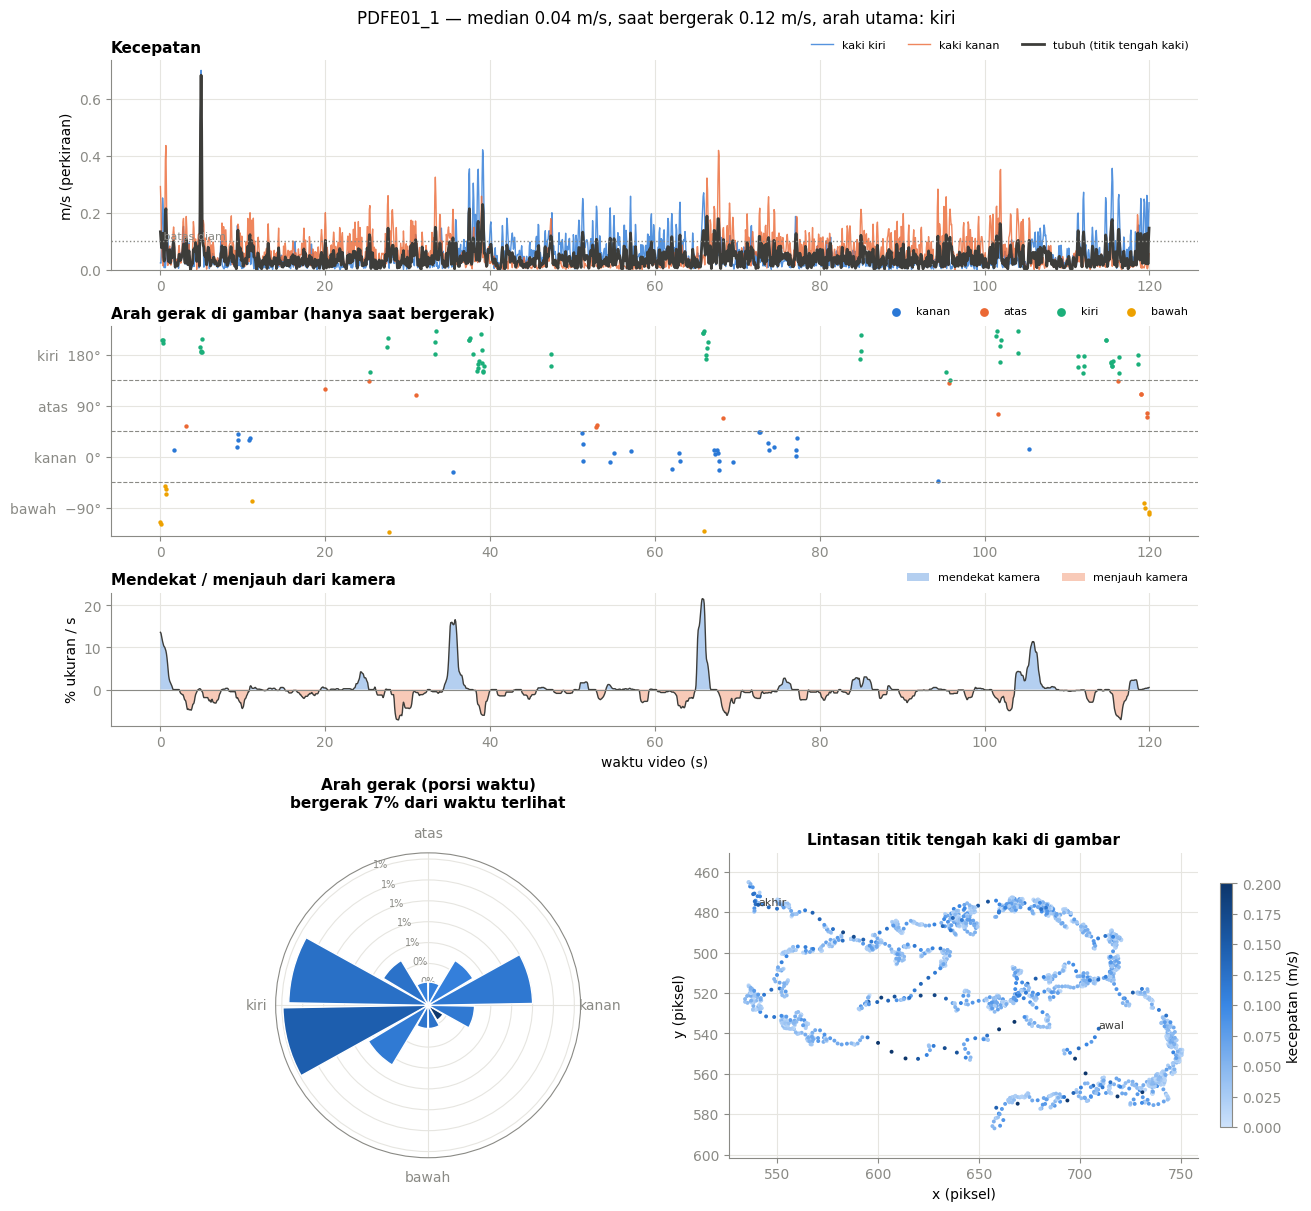

video_id,PDFE01_1
duration_s,120.0
valid_frac,1.0
scale_source,tulang_kering
speed_median_mps,0.038
speed_p90_mps,0.087
speed_moving_median_mps,0.12
L_speed_median_mps,0.036
R_speed_median_mps,0.045
moving_frac,0.069
main_direction,kiri


Grafik 73 video disimpan di D:\SE Parkinson\outputs\03a_arah_kecepatan\balanced_s2_det0.1\figures (34 s)


In [6]:
if "CELLS_DONE" not in globals():
    raise RuntimeError("Jalankan sel 1 (Pengaturan) dulu: kernel di-restart atau ada sel yang terlewat.")
_require('extract')

def plot_video(vid, show=True):
    F = FRAMES[vid]
    t = F["t_s"].to_numpy()
    fig = plt.figure(figsize=(13, 12), constrained_layout=True)
    gs = fig.add_gridspec(4, 2, height_ratios=[1.1, 1.1, 0.7, 1.6])
    ax_s = fig.add_subplot(gs[0, :]); ax_d = fig.add_subplot(gs[1, :], sharex=ax_s); ax_a = fig.add_subplot(gs[2, :], sharex=ax_s)
    ax_r = fig.add_subplot(gs[3, 0], projection="polar"); ax_t = fig.add_subplot(gs[3, 1])
    for ax in (ax_s, ax_d, ax_a):
        for a, b in runs(F["valid"].to_numpy() == 0):
            ax.axvspan(t[a], t[min(b, len(t) - 1)], color=COL["grid"], lw=0, zorder=0)

    # speed
    for s in SIDES:
        ax_s.plot(t, F[f"{s}_speed_mps"], color=COL[s], lw=1, alpha=0.8, label=f"kaki {SIDE_TXT[s]}")
    ax_s.plot(t, F["speed_mps"], color=COL["body"], lw=2, label="tubuh (titik tengah kaki)")
    ax_s.axhline(MOVE_MIN_MPS, color=COL["muted"], ls=":", lw=1)
    ax_s.text(t[0], MOVE_MIN_MPS, " batas diam", va="bottom", fontsize=8, color=COL["muted"])
    ax_s.set_ylabel("m/s (perkiraan)"); ax_s.set_title("Kecepatan", loc="left")
    ax_s.legend(loc="lower right", bbox_to_anchor=(1, 1), fontsize=8, ncol=3)
    ax_s.set_ylim(bottom=0)

    # direction over time
    for k in DIRS:
        m = (F["direction"] == k).to_numpy()
        yv = F["direction_deg"].to_numpy()[m]
        yv = np.where(yv < -135, yv + 360, yv)          # axis -135..225: every sector is one continuous band
        ax_d.scatter(t[m], yv, s=10, color=DIR_COL[k], label=k, lw=0)
    for y in (-45, 45, 135):
        ax_d.axhline(y, color=COL["muted"], ls="--", lw=0.8)
    ax_d.set_yticks([-90, 0, 90, 180]); ax_d.set_yticklabels(["bawah  −90°", "kanan  0°", "atas  90°", "kiri  180°"])
    ax_d.set_ylim(-140, 230); ax_d.set_title("Arah gerak di gambar (hanya saat bergerak)", loc="left")
    ax_d.legend(loc="lower right", bbox_to_anchor=(1, 1), fontsize=8, ncol=4, markerscale=2)

    # approach / recede
    ap = F["approach_rate"].to_numpy() * 100
    ax_a.fill_between(t, 0, ap, where=ap > 0, color=COL["near"], alpha=0.35, lw=0, label="mendekat kamera")
    ax_a.fill_between(t, 0, ap, where=ap < 0, color=COL["far"], alpha=0.35, lw=0, label="menjauh kamera")
    ax_a.plot(t, ap, color=COL["body"], lw=1)
    ax_a.axhline(0, color=COL["muted"], lw=0.8)
    ax_a.set_ylabel("% ukuran / s"); ax_a.set_xlabel("waktu video (s)")
    ax_a.set_title("Mendekat / menjauh dari kamera", loc="left")
    ax_a.legend(loc="lower right", bbox_to_anchor=(1, 1), fontsize=8, ncol=2)

    # rose: time share per 30-degree sector, coloured by median speed
    mv = F[F["direction"].isin(DIRS)]
    bins = np.radians(np.arange(-180, 181, 30))
    th = np.radians(mv["direction_deg"].to_numpy())
    cnt, _ = np.histogram(th, bins)
    share = cnt / max(1, F["valid"].sum())
    med = [mv["speed_mps"].to_numpy()[(th >= bins[i]) & (th < bins[i + 1])] for i in range(len(cnt))]
    med = np.array([np.median(x) if len(x) else 0 for x in med])
    vmax = max(0.2, float(np.nanpercentile(F["speed_mps"], 95)) if F["valid"].any() else 0.2)
    ax_r.bar(bins[:-1] + np.radians(15), share, width=np.radians(28), color=SPEED_CMAP(np.clip(med / vmax, 0, 1)),
             edgecolor="white", lw=1)
    ax_r.set_theta_zero_location("E"); ax_r.set_theta_direction(1)
    ax_r.set_xticks(np.radians([0, 90, 180, 270])); ax_r.set_xticklabels(["kanan", "atas", "kiri", "bawah"])
    ax_r.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax_r.set_rlabel_position(112); ax_r.tick_params(axis="y", labelsize=7)
    ax_r.set_title(f"Arah gerak (porsi waktu)\nbergerak {len(mv) / max(1, F['valid'].sum()):.0%} dari waktu terlihat", pad=14)

    # trajectory coloured by speed
    ok = F[["center_x", "center_y", "speed_mps"]].notna().all(axis=1)
    sc = ax_t.scatter(F.loc[ok, "center_x"], F.loc[ok, "center_y"], c=F.loc[ok, "speed_mps"], cmap=SPEED_CMAP, vmin=0,
                      vmax=vmax, s=8, lw=0)
    if ok.any():
        i0, i1 = np.where(ok)[0][[0, -1]]
        ax_t.annotate("awal", (F.at[i0, "center_x"], F.at[i0, "center_y"]), fontsize=8, color=COL["body"])
        ax_t.annotate("akhir", (F.at[i1, "center_x"], F.at[i1, "center_y"]), fontsize=8, color=COL["body"])
    ax_t.invert_yaxis(); ax_t.set_aspect("equal", adjustable="datalim")
    ax_t.set_title("Lintasan titik tengah kaki di gambar"); ax_t.set_xlabel("x (piksel)"); ax_t.set_ylabel("y (piksel)")
    cb = fig.colorbar(sc, ax=[ax_r, ax_t], shrink=0.8, pad=0.02); cb.set_label("kecepatan (m/s)")
    r = SUMMARY.loc[vid]
    fig.suptitle(f"{vid} — median {r['speed_median_mps']:.2f} m/s, saat bergerak {r['speed_moving_median_mps']:.2f} m/s, "
                 f"arah utama: {r['main_direction']}", fontsize=12)
    fig.savefig(FIG_DIR / f"{vid}_arah_kecepatan.png", dpi=110)
    if show:
        plt.show()
    else:
        plt.close(fig)

vid = VIEW_VIDEO if VIEW_VIDEO in FRAMES else SUMMARY["valid_frac"].idxmax()
plot_video(vid)
display(SUMMARY.loc[[vid]].T)
if SAVE_ALL_FIGS:
    t0 = time.time()
    for v in FRAMES:
        if v != vid:
            plot_video(v, show=False)
    print(f"Grafik {len(FRAMES)} video disimpan di {FIG_DIR} ({time.time() - t0:.0f} s)")
_done('one-video')

## 6. Grafik semua video

* **Kiri** — median kecepatan tubuh per video (batang) dan persentil-90 (titik), urut dari yang paling lambat.
* **Kanan** — porsi waktu tiap arah per video (urutan video sama). Abu = diam.

In [ ]:
if "CELLS_DONE" not in globals():
    raise RuntimeError("Jalankan sel 1 (Pengaturan) dulu: kernel di-restart atau ada sel yang terlewat.")
_require('extract')

S = SUMMARY.sort_values("speed_median_mps")
h = max(4, 0.22 * len(S) + 1.5)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, h), sharey=True, constrained_layout=True,
                             gridspec_kw={"width_ratios": [1, 1.3]})
y = np.arange(len(S))
a1.barh(y, S["speed_median_mps"], color="#3987e5", height=0.7, label="median")
a1.plot(S["speed_p90_mps"], y, "o", ms=4, color=COL["body"], label="persentil-90")
a1.set_yticks(y); a1.set_yticklabels(S.index, fontsize=7 if len(S) > 40 else 9)
a1.set_xlabel("kecepatan tubuh (m/s, perkiraan)"); a1.set_title("Kecepatan per video"); a1.legend(loc="lower right", fontsize=8)
a1.grid(axis="y", visible=False)
left = np.zeros(len(S))
for k in DIRS + ["diam"]:
    w = S[f"frac_{k}"].to_numpy()
    a2.barh(y, w, left=left, color=DIR_COL[k], height=0.7, edgecolor="white", lw=1, label=k)
    for yi, (l, wi) in enumerate(zip(left, w)):
        if wi >= 0.12:
            a2.text(l + wi / 2, yi, f"{wi:.0%}", ha="center", va="center", fontsize=7, color="#1a1a19")
    left += w
a2.set_xlim(0, 1); a2.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
a2.set_title("Porsi waktu tiap arah"); a2.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02 + 0.6 / h), ncol=5, fontsize=8)
a2.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "semua_video_arah_kecepatan.png", dpi=110)
plt.show()

fig, axs = plt.subplots(1, 2, figsize=(13, 3.6), constrained_layout=True)
axs[0].hist(SUMMARY["speed_moving_median_mps"].dropna(), bins=20, color="#3987e5", rwidth=0.9)
axs[0].set_title("Median kecepatan saat bergerak (semua video)"); axs[0].set_xlabel("m/s"); axs[0].set_ylabel("jumlah video")
main = SUMMARY["main_direction"].value_counts().reindex(DIRS + ["diam"]).fillna(0)
bars = axs[1].bar(main.index, main.values, color=[DIR_COL[k] for k in main.index], width=0.6)
axs[1].bar_label(bars, fontsize=9); axs[1].set_title("Arah utama per video"); axs[1].set_ylabel("jumlah video")
fig.savefig(FIG_DIR / "semua_video_ringkas.png", dpi=110)
plt.show()
display(SUMMARY.drop(columns=["scale_source"]).describe().T[["mean", "50%", "min", "max"]].round(3))
_done('overview')

### Kamus kolom `frames/<video_id>.csv`
| Kolom | Arti |
|---|---|
| `t_s`, `frame_idx` | waktu video (s), nomor frame |
| `patient`, `quality`, `valid` | kotak pasien dipakai; kualitas dari review; ada data kecepatan |
| `scale_px` | panjang tulang kering (piksel) untuk skala |
| `L_/R_ankle_x, _y`, `L_/R_speed_mps` | posisi ankle (piksel) dan kecepatannya |
| `center_x, center_y` | titik tengah dua ankle (piksel) |
| `vx_mps`, `vy_up_mps`, `speed_mps` | komponen kecepatan (kanan +, atas +) dan besarnya |
| `direction_deg`, `direction` | sudut arah (0° kanan, 90° atas) dan labelnya (`kanan/atas/kiri/bawah/diam`) |
| `approach_rate`, `depth_motion` | perubahan ukuran per detik (> 0 mendekat) dan labelnya |